## VINDPROGNOSE BERGEN
Hvor mye strøm kan en vindturbin ved Bergen produsere, og kan vi forutsi produksjonen fra værdata?

In [71]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

## Hente data

Vi henter vindhastighet time for time i 10 og 120 meters høyde fra Open-Meteo sitt historiske arkiv.

In [72]:
def hent_vinddata(start, slutt, lat=60.39, lon=5.32):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "wind_speed_10m,wind_speed_120m",
        "start_date": start,
        "end_date": slutt,
        "wind_speed_unit": "ms",
        "timezone": "Europe/Oslo"
    }

    svar = requests.get(url, params=params)
    if svar.status_code != 200:
        raise Exception(f"Feil fra API-et: {svar.status_code} {svar.text}")

    data = svar.json()
    
    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    return df

In [73]:
df = hent_vinddata("2025-01-01", "2025-12-31")
print(df.shape)
print(df.isna().sum())

(8760, 3)
time               0
wind_speed_10m     0
wind_speed_120m    0
dtype: int64


Datasettet har 8760 timer (hele 2025) og ingen manglende verdier

## Utforske data

In [74]:
df["maaned"] = df["time"].dt.month
df

,time,wind_speed_10m,wind_speed_120m,maaned
0,2025-01-01 00:00:00,2.71,5.02,1
1,2025-01-01 01:00:00,2.52,4.74,1
2,2025-01-01 02:00:00,3.34,6.09,1
3,2025-01-01 03:00:00,3.32,6.25,1
4,2025-01-01 04:00:00,2.29,4.39,1
...,...,...,...,...
8755,2025-12-31 19:00:00,3.85,7.42,12
8756,2025-12-31 20:00:00,3.64,8.02,12
8757,2025-12-31 21:00:00,6.10,10.97,12
8758,2025-12-31 22:00:00,3.32,7.01,12


In [75]:
per_maaned = df.groupby("maaned")["wind_speed_120m"].mean()
per_maaned.sort_values()

maaned
7     3.487003
4     4.635083
9     4.800125
6     5.912653
8     5.962191
1     6.007863
5     6.057608
3     6.187258
10    6.239140
11    6.370417
2     6.412619
12    6.571116
Name: wind_speed_120m, dtype: float64

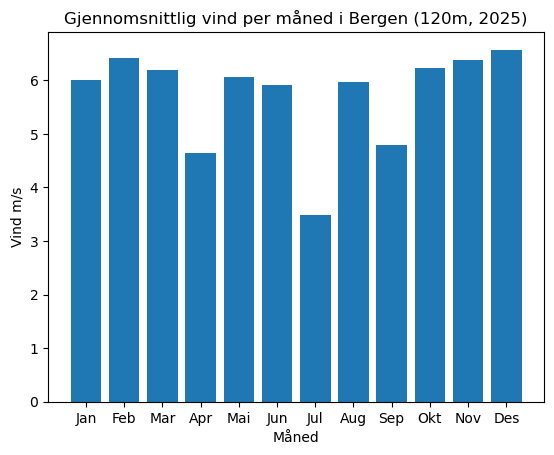

In [78]:
plt.bar(per_maaned.index, per_maaned.values)
plt.title("Gjennomsnittlig vind per måned i Bergen (120m, 2025)")
plt.xlabel("Måned")
plt.ylabel("Vind m/s")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Des"])
plt.savefig("grafer/vind_per_maaned.png", bbox_inches="tight")
plt.show()

Grafen viser oss gjennomsnittlig vind(m/s) per måned i Bergen for året 2025, på 120m høyde.

Vi ser at det blåser minst i månedene: April, Juli og September. Det blåser mest i månedene: Februar, November og Desember.

Vinteren er generelt mer vindfull enn sommeren: Desember har nesten dobbelt så høy snittvind som juli. April og september skiller seg ut med lav vind, men siden dette bare er ett år, kan det være tilfeldig variasjon.